# Task 01 – Stroke Prediction (Binary Classification)

**Problem statement:** predict whether a patient is likely to have a **stroke** from their age, health conditions and lifestyle,
so that high-risk patients can be checked early.

**Task type:** supervised **binary classification** – target `stroke` (1 = stroke, 0 = no stroke).

**Dataset:** [Kaggle – Stroke Prediction Dataset](https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset) – 5,110 patients, 11 features + target.

| Column | Meaning |
|---|---|
| id | patient id (no information) |
| gender | Male / Female / Other |
| age | age in years |
| hypertension / heart_disease | 1 = yes, 0 = no |
| ever_married | Yes / No |
| work_type | Private, Self-employed, Govt_job, children, Never_worked |
| Residence_type | Urban / Rural |
| avg_glucose_level | average blood glucose level |
| bmi | body mass index |
| smoking_status | never smoked, formerly smoked, smokes, Unknown |
| **stroke** | **target** |

# Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')
os.environ['PYTHONWARNINGS'] = 'ignore'   # also hide warnings inside the parallel workers (n_jobs=-1)
%matplotlib inline
sns.set_theme(style='whitegrid')

# Read data

In [2]:
df = pd.read_csv('dataset/healthcare-dataset-stroke-data.csv')
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
df.shape

(5110, 12)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [5]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


# Data Understanding

In [6]:
print(df['stroke'].value_counts())
print((df['stroke'].value_counts(normalize=True) * 100).round(1))

stroke
0    4861
1     249
Name: count, dtype: int64
stroke
0    95.1
1     4.9
Name: proportion, dtype: float64


Only **4.9 %** of the patients had a stroke → the data is **very imbalanced**.
A model that always says "no stroke" gets 95 % accuracy but is useless, so accuracy is **not** the main metric.
We use **ROC-AUC** to compare and tune the models, and we look closely at **Recall** (how many stroke patients we catch), Precision, F1 and the Precision-Recall curve.

In [7]:
for col in ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']:
    print(df[col].value_counts().to_dict())

{'Female': 2994, 'Male': 2115, 'Other': 1}
{'Yes': 3353, 'No': 1757}
{'Private': 2925, 'Self-employed': 819, 'children': 687, 'Govt_job': 657, 'Never_worked': 22}
{'Urban': 2596, 'Rural': 2514}
{'never smoked': 1892, 'Unknown': 1544, 'formerly smoked': 885, 'smokes': 789}


# Data Cleaning

In [8]:
df.drop('id', axis=1, inplace=True)    # just a row number, no information
df = df[df['gender'] != 'Other']        # only 1 patient -> too rare to learn from
df.reset_index(drop=True, inplace=True)
df.shape

(5109, 11)

In [9]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

- `bmi` has 201 missing values → filled with the **median inside the Pipeline** (learned from the training data only).
- `smoking_status = Unknown` (30 % of the rows) is kept as its own category – dropping it would lose a lot of data.

In [10]:
print('Number of duplicate rows : ', df.duplicated().sum())

Number of duplicate rows :  0


# EDA & Statistical Analysis

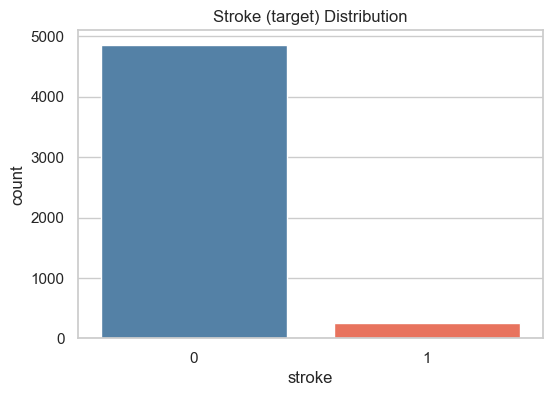

In [11]:
plt.figure(figsize=(6, 4))
sns.countplot(x='stroke', data=df, palette=['steelblue', 'tomato'])
plt.title('Stroke (target) Distribution')
plt.show()

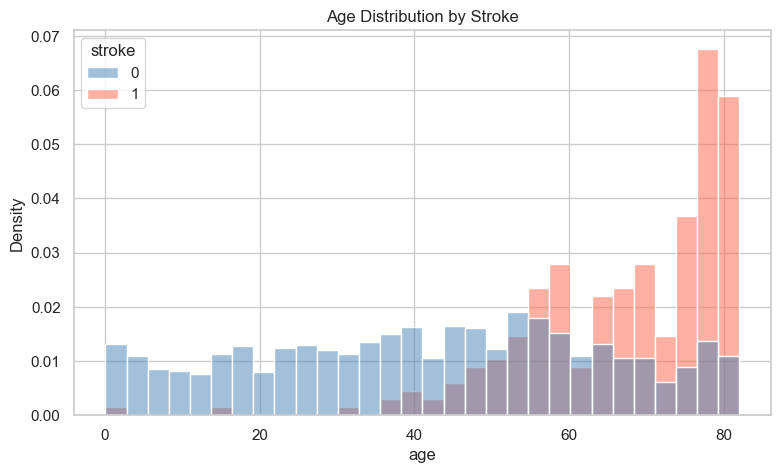

In [12]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='age', hue='stroke', stat='density', common_norm=False, bins=30, palette=['steelblue', 'tomato'])
plt.title('Age Distribution by Stroke')
plt.show()

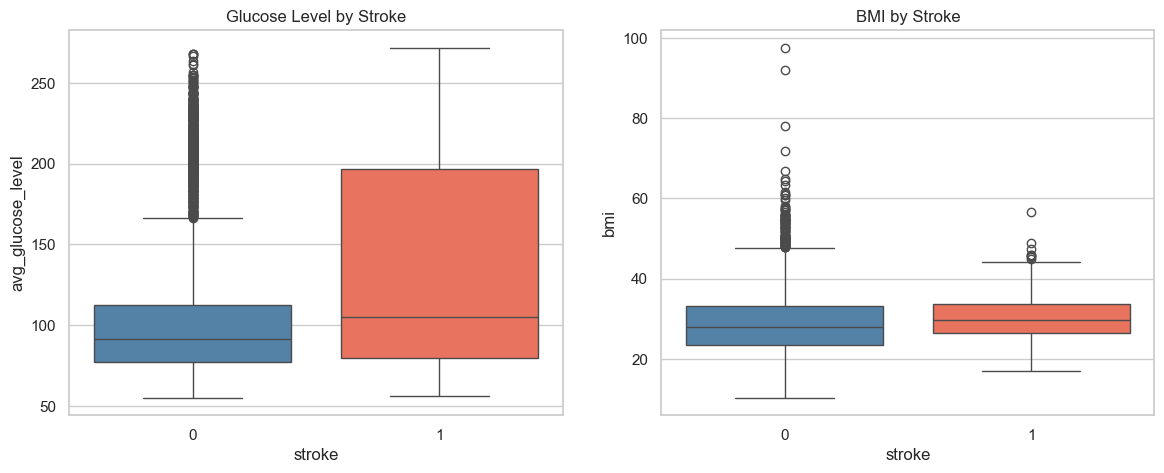

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x='stroke', y='avg_glucose_level', data=df, ax=ax[0], palette=['steelblue', 'tomato'])
ax[0].set_title('Glucose Level by Stroke')
sns.boxplot(x='stroke', y='bmi', data=df, ax=ax[1], palette=['steelblue', 'tomato'])
ax[1].set_title('BMI by Stroke')
plt.show()

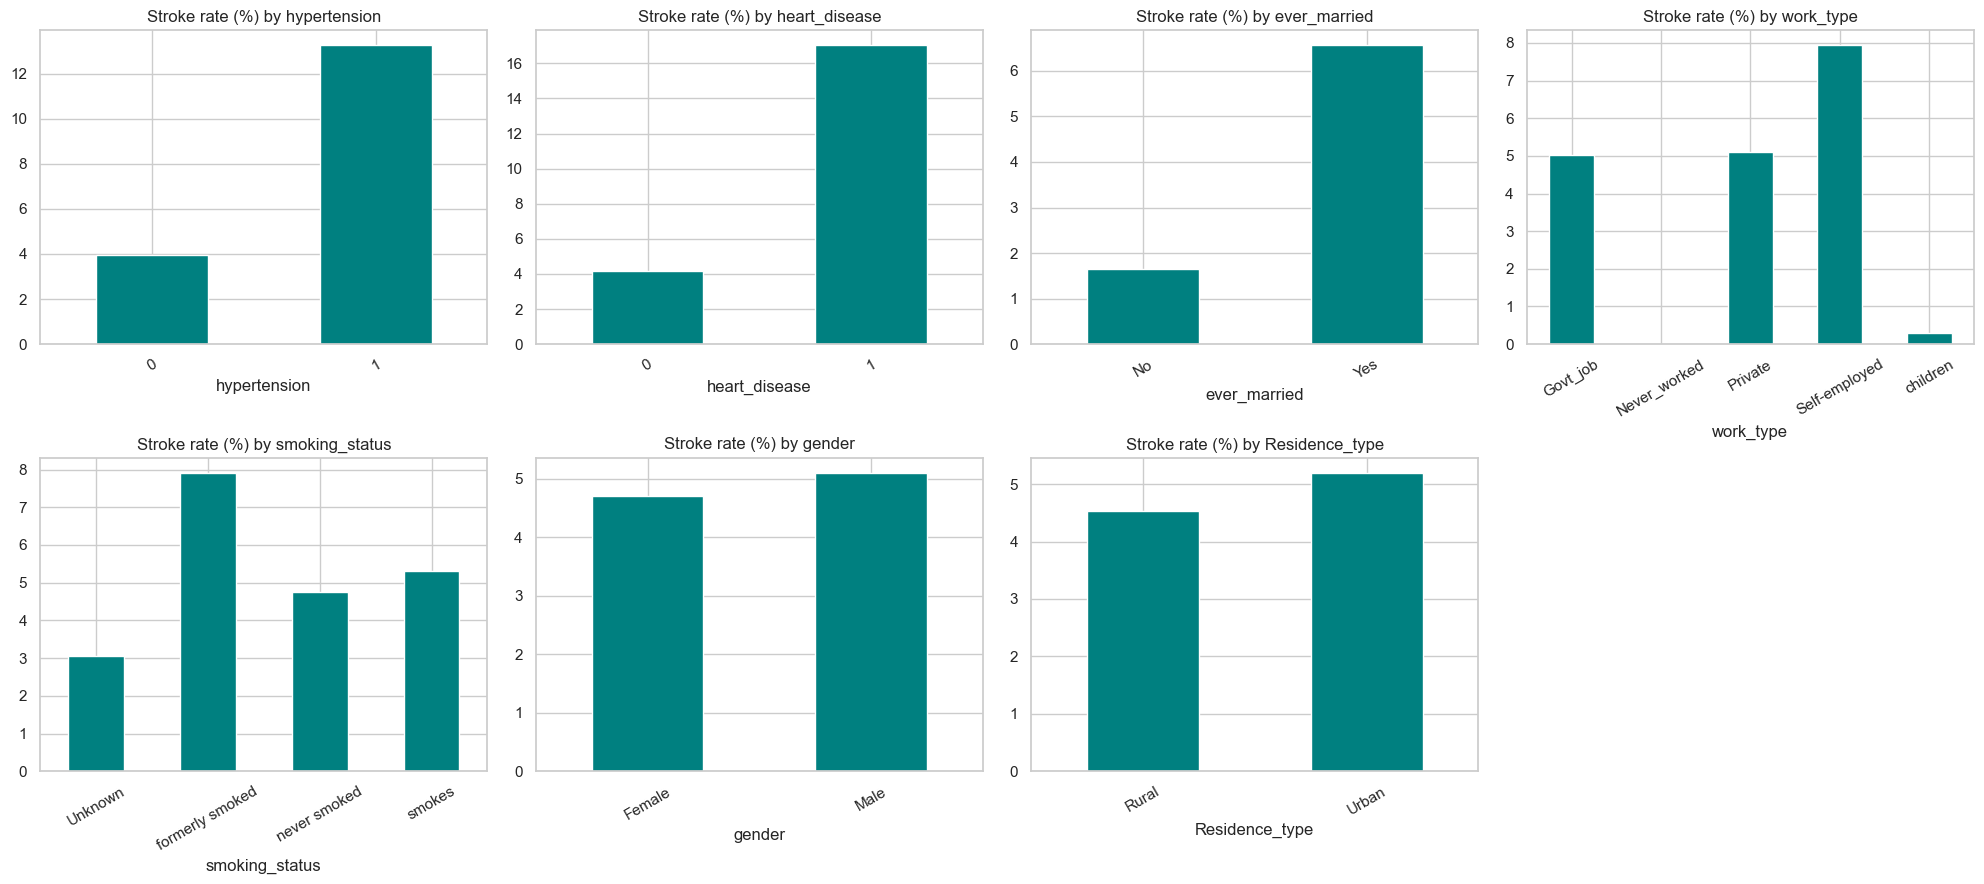

In [14]:
cat_features = ['hypertension', 'heart_disease', 'ever_married', 'work_type', 'smoking_status', 'gender', 'Residence_type']

fig, ax = plt.subplots(2, 4, figsize=(20, 9))
ax = ax.flatten()
for i, col in enumerate(cat_features):
    (df.groupby(col)['stroke'].mean() * 100).plot(kind='bar', color='teal', ax=ax[i])
    ax[i].set_title('Stroke rate (%) by ' + col)
    ax[i].tick_params(axis='x', rotation=30)
ax[-1].axis('off')
plt.tight_layout()
plt.show()

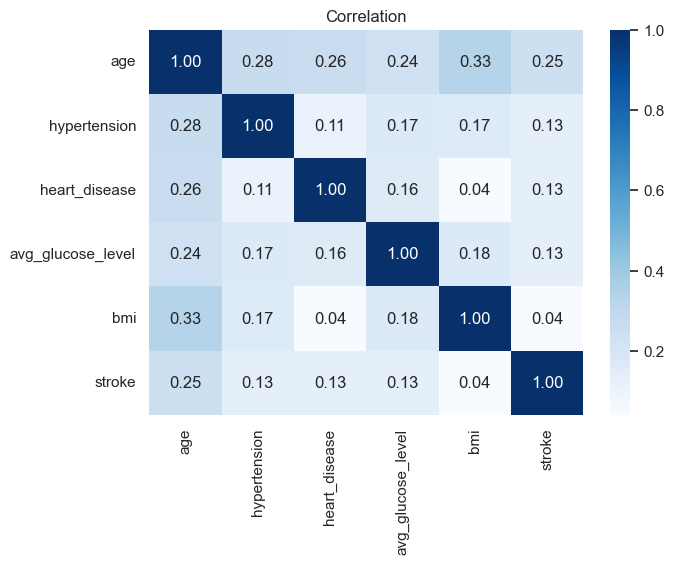

In [15]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke']].corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation')
plt.show()

## Statistical tests

In [16]:
from scipy.stats import ttest_ind, chi2_contingency

print('t-test (numbers): is the mean different between stroke and no-stroke patients?')
for col in ['age', 'avg_glucose_level', 'bmi']:
    a = df[df['stroke'] == 1][col].dropna()
    b = df[df['stroke'] == 0][col].dropna()
    print(f'  {col:18s} mean stroke = {a.mean():6.1f}   mean no stroke = {b.mean():6.1f}   p-value = {ttest_ind(a, b).pvalue:.4f}')

print('\nChi-square test (categories): is the stroke rate different between the groups?')
for col in cat_features:
    p = chi2_contingency(pd.crosstab(df[col], df['stroke']))[1]
    print(f'  {col:18s} p-value = {p:.4f}')

t-test (numbers): is the mean different between stroke and no-stroke patients?
  age                mean stroke =   67.7   mean no stroke =   42.0   p-value = 0.0000
  avg_glucose_level  mean stroke =  132.5   mean no stroke =  104.8   p-value = 0.0000
  bmi                mean stroke =   30.5   mean no stroke =   28.8   p-value = 0.0030

Chi-square test (categories): is the stroke rate different between the groups?
  hypertension       p-value = 0.0000
  heart_disease      p-value = 0.0000
  ever_married       p-value = 0.0000
  work_type          p-value = 0.0000
  smoking_status     p-value = 0.0000
  gender             p-value = 0.5598
  Residence_type     p-value = 0.2998


**EDA findings**
- **Age is the strongest sign:** stroke patients are much older (mean 67.7 vs 42.0 years); after 60 the stroke rate jumps from 1.8 % to 13.2 %.
- **Glucose:** stroke patients have a higher average glucose (132.5 vs 104.8). **BMI** is only a little higher (30.5 vs 28.8).
- **Health conditions:** hypertension (13 % vs 4 %) and heart disease (17 % vs 4 %) triple the stroke rate.
- `ever_married`, `work_type` (self-employed highest, children almost 0) and `smoking_status` also differ – partly because they are linked to age.
- **Statistical tests:** age, glucose and BMI differ significantly (t-test p < 0.01). Hypertension, heart disease, marriage, work type and smoking are significant (chi-square p < 0.001),
  but **gender (p = 0.56) and Residence_type (p = 0.30) are not**.

# Outliers

In [17]:
for col in ['age', 'avg_glucose_level', 'bmi']:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    outliers = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    print(f'{col:18s} outliers = {outliers.sum():4d}   stroke rate inside the outliers = {df.loc[outliers, "stroke"].mean() * 100:.1f} %')

age                outliers =    0   stroke rate inside the outliers = nan %
avg_glucose_level  outliers =  627   stroke rate inside the outliers = 13.4 %
bmi                outliers =  110   stroke rate inside the outliers = 1.8 %


- The high glucose values are **real patients** (diabetics), and their stroke rate is **13.4 %** – almost **3 times the average (4.9 %)** → they carry important information, so they are **kept**.
- The high BMI values (> 47) are possible (severe obesity) and their stroke rate is low (1.8 %), so they are not errors either; removing rows would also remove some of the few stroke cases.
- So no rows are removed; the median imputer and the `StandardScaler` handle the numbers, and tree models are not affected by outliers.

# Feature Engineering

In [18]:
df['High_Glucose'] = (df['avg_glucose_level'] >= 140).astype(int)   # diabetic glucose level
df['Senior'] = (df['age'] >= 60).astype(int)                          # stroke risk jumps after 60
print(df.groupby('High_Glucose')['stroke'].mean().round(3))
print(df.groupby('Senior')['stroke'].mean().round(3))

High_Glucose
0    0.036
1    0.113
Name: stroke, dtype: float64
Senior
0    0.018
1    0.132
Name: stroke, dtype: float64


Both flags show a big jump in the stroke rate (glucose ≥ 140: ≈ 11 % vs 4 %, age ≥ 60: ≈ 13 % vs 2 %).
They help simple models (like Logistic Regression) that can't learn a sudden jump by themselves.
They are simple row-by-row rules → **no data leakage**.

# Feature Selection

The chi-square test showed that **gender** (p = 0.56) and **Residence_type** (p = 0.30) have **no significant relation** with stroke (p > 0.05),
and their stroke rates are almost the same in each group → they are **dropped**. All other features are significant (p < 0.05) and kept.

In [19]:
num_cols = ['age', 'avg_glucose_level', 'bmi', 'hypertension', 'heart_disease', 'High_Glucose', 'Senior']
cat_cols = ['ever_married', 'work_type', 'smoking_status']

# Split data

In [20]:
from sklearn.model_selection import train_test_split

X = df[num_cols + cat_cols]
y = df['stroke']

# stratify=y keeps the same 4.9 % stroke rate in train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print('X_train = ', X_train.shape, ' y_train = ', y_train.shape, ' stroke cases =', y_train.sum())
print('X_test  = ', X_test.shape, ' y_test  = ', y_test.shape, ' stroke cases =', y_test.sum())

X_train =  (4087, 10)  y_train =  (4087,)  stroke cases = 199
X_test  =  (1022, 10)  y_test  =  (1022,)  stroke cases = 50


# Preprocessing (Pipeline + ColumnTransformer + SMOTE)

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

def make_pipeline(model):
    return ImbPipeline([
        ('preprocessor', preprocessor),
        ('smote', SMOTE(random_state=42)),
        ('model', model)
    ])

- **Imputation:** median for numbers (robust to outliers), most frequent value for categories.
- **Scaling:** `StandardScaler` – needed by Logistic Regression, KNN and SVM.
- **Encoding:** `OneHotEncoder` because the categories have no order.
- **SMOTE:** creates synthetic stroke patients so the model sees both classes equally.
  It is **inside the Pipeline**, so it runs only on the **training folds** – the validation and test data stay real (doing SMOTE before the split would leak copies of the same patients into the test data).
- `ImbPipeline` (from imbalanced-learn) is used because the normal sklearn `Pipeline` doesn't allow a resampling step.

# Models

| Model | Why it is tried |
|---|---|
| Logistic Regression | simple, explainable baseline for yes/no problems |
| KNN | patients similar to each other have similar risk |
| Decision Tree | easy-to-read rules, but overfits |
| Random Forest / Extra Trees | many trees averaged → less overfitting |
| SVM | finds the best separating boundary (RBF kernel for non-linear) |
| Naive Bayes | very fast probabilistic model, good baseline |
| Gradient Boosting / AdaBoost | each tree fixes the mistakes of the previous ones |
| XGBoost / LightGBM | fast, regularized boosting – usually strong on tabular data |

Regression models (Linear Regression, Ridge, ...) are **excluded** because the target is a class (0 / 1), not a number.

In [22]:
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
                             classification_report, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

In [23]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(probability=True, random_state=42),
    'Naive Bayes': GaussianNB(),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'AdaBoost': AdaBoostClassifier(algorithm='SAMME', random_state=42),
    'Extra Trees': ExtraTreesClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42),
    'LightGBM': LGBMClassifier(random_state=42, verbose=-1),
}

## Model comparison with 5-fold stratified cross-validation (training data only)

In [24]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'ROC-AUC': 'roc_auc', 'AP': 'average_precision', 'Recall': 'recall', 'Precision': 'precision', 'F1': 'f1', 'Accuracy': 'accuracy'}

results = {}
for name, model in models.items():
    cv = cross_validate(make_pipeline(model), X_train, y_train, cv=kfold, scoring=scoring, n_jobs=-1)
    results[name] = {metric: cv['test_' + metric].mean() for metric in scoring}
    print(f"{name:20s} ROC-AUC = {results[name]['ROC-AUC']:.4f}   Recall = {results[name]['Recall']:.3f}")

Logistic Regression  ROC-AUC = 0.8394   Recall = 0.784


KNN                  ROC-AUC = 0.6884   Recall = 0.447


Decision Tree        ROC-AUC = 0.5732   Recall = 0.221


Random Forest        ROC-AUC = 0.8194   Recall = 0.156


SVM                  ROC-AUC = 0.7898   Recall = 0.603
Naive Bayes          ROC-AUC = 0.7973   Recall = 0.950


Gradient Boosting    ROC-AUC = 0.8047   Recall = 0.372


AdaBoost             ROC-AUC = 0.8166   Recall = 0.714


Extra Trees          ROC-AUC = 0.7903   Recall = 0.161
XGBoost              ROC-AUC = 0.8044   Recall = 0.186


LightGBM             ROC-AUC = 0.8195   Recall = 0.171


In [25]:
comparison = pd.DataFrame(results).T.sort_values('ROC-AUC', ascending=False)
comparison.round(4)

,ROC-AUC,AP,Recall,Precision,F1,Accuracy
Logistic Regression,0.8394,0.1990,0.7838,0.1338,0.2285,0.7419
LightGBM,0.8195,0.1559,0.1708,0.1912,0.1799,0.9239
Random Forest,0.8194,0.1611,0.1555,0.1431,0.1485,0.9156
AdaBoost,0.8166,0.1489,0.7141,0.1363,0.2285,0.7619
Gradient Boosting,0.8047,0.1546,0.3723,0.1419,0.2049,0.8591
XGBoost,0.8044,0.1494,0.1860,0.1565,0.1697,0.9117
Naive Bayes,0.7973,0.1609,0.9496,0.0693,0.1292,0.3763
Extra Trees,0.7903,0.1381,0.1605,0.1402,0.1495,0.9114
SVM,0.7898,0.1480,0.6032,0.1222,0.2030,0.7680
KNN,0.6884,0.0962,0.4473,0.1268,0.1974,0.8226


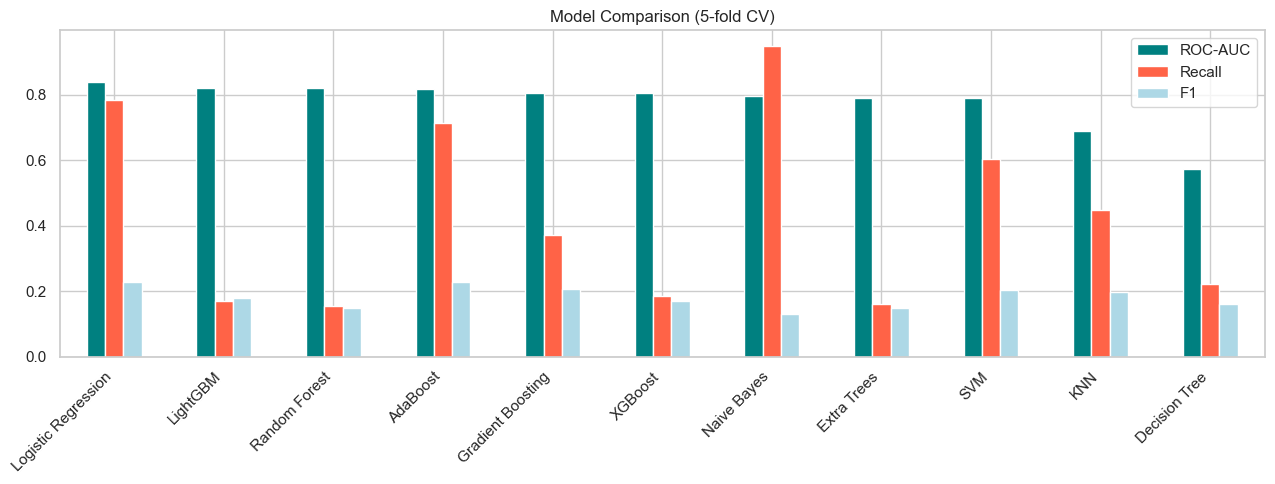

In [26]:
comparison[['ROC-AUC', 'Recall', 'F1']].plot(kind='bar', figsize=(13, 5), color=['teal', 'tomato', 'lightblue'])
plt.title('Model Comparison (5-fold CV)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Comparison results (5-fold stratified CV, all with SMOTE inside the pipeline)**
- **Logistic Regression is the best** (ROC-AUC 0.839) and also catches **78 % of stroke patients** (recall). With few positive cases (199 in training) and a mostly
  "straight-line" risk (older + higher glucose + hypertension → higher risk), a simple model generalizes best.
- **Tree ensembles** (LightGBM 0.820, Random Forest 0.819, XGBoost 0.804) rank patients well (good ROC-AUC) but at the default 0.5 threshold they catch only 16 – 19 % of strokes:
  they learn the SMOTE points too well and stay too "confident" on "no stroke".
- **Naive Bayes** catches 95 % of strokes but flags almost everybody (precision 7 %, accuracy 38 %) → not useful.
- **Decision Tree** (0.57) and **KNN** (0.69) are the weakest: one tree overfits the few stroke cases, and KNN is confused by the synthetic SMOTE points.
- **Accuracy is misleading here:** Random Forest has 92 % accuracy but misses 84 % of the stroke patients.
- The **top 3 by ROC-AUC (Logistic Regression, LightGBM, Random Forest)** are tuned.

# GridSearchCV (top 3 models)

A parameter grid is prepared for every model; the **top 3 models by CV ROC-AUC** are tuned with 5-fold stratified cross-validation on the training data.

In [27]:
param_grids = {
    'Logistic Regression': {'model__C': [0.01, 0.1, 1, 10]},
    'KNN': {'model__n_neighbors': [5, 15, 31], 'model__weights': ['uniform', 'distance']},
    'Decision Tree': {'model__max_depth': [3, 5, 8], 'model__min_samples_leaf': [5, 20, 50]},
    'Random Forest': {'model__n_estimators': [200, 400], 'model__max_depth': [5, 10, None], 'model__min_samples_leaf': [1, 5]},
    'SVM': {'model__C': [0.1, 1, 10], 'model__kernel': ['rbf', 'linear']},
    'Naive Bayes': {'model__var_smoothing': [1e-9, 1e-7, 1e-5]},
    'Gradient Boosting': {'model__n_estimators': [100, 300], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [2, 3]},
    'AdaBoost': {'model__n_estimators': [50, 200], 'model__learning_rate': [0.1, 1.0]},
    'Extra Trees': {'model__n_estimators': [200, 400], 'model__max_depth': [5, 10, None], 'model__min_samples_leaf': [1, 5]},
    'XGBoost': {'model__n_estimators': [100, 300], 'model__max_depth': [2, 4], 'model__learning_rate': [0.05, 0.1]},
    'LightGBM': {'model__n_estimators': [100, 300], 'model__num_leaves': [7, 15], 'model__learning_rate': [0.05, 0.1]},
}

In [28]:
top_models = comparison.index[:3]
grids = {}

for name in top_models:
    grid = GridSearchCV(make_pipeline(models[name]), param_grids[name], cv=kfold, scoring='roc_auc', n_jobs=-1)
    grid.fit(X_train, y_train)
    grids[name] = grid

    print('=' * 60)
    print(name)
    print('Parameter grid :', param_grids[name])
    print('best_params_   :', grid.best_params_)
    print('best_score_    :', round(grid.best_score_, 4), '(CV ROC-AUC)')

Logistic Regression
Parameter grid : {'model__C': [0.01, 0.1, 1, 10]}
best_params_   : {'model__C': 0.1}
best_score_    : 0.8401 (CV ROC-AUC)


LightGBM
Parameter grid : {'model__n_estimators': [100, 300], 'model__num_leaves': [7, 15], 'model__learning_rate': [0.05, 0.1]}
best_params_   : {'model__learning_rate': 0.1, 'model__n_estimators': 100, 'model__num_leaves': 15}
best_score_    : 0.8176 (CV ROC-AUC)


Random Forest
Parameter grid : {'model__n_estimators': [200, 400], 'model__max_depth': [5, 10, None], 'model__min_samples_leaf': [1, 5]}
best_params_   : {'model__max_depth': None, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}
best_score_    : 0.8292 (CV ROC-AUC)


## Before vs after tuning (cross-validation ROC-AUC)

In [29]:
tuning = pd.DataFrame({
    'CV ROC-AUC before tuning': comparison.loc[top_models, 'ROC-AUC'],
    'CV ROC-AUC after tuning': [grids[name].best_score_ for name in top_models],
})
tuning['Improvement'] = tuning['CV ROC-AUC after tuning'] - tuning['CV ROC-AUC before tuning']
tuning['Best params'] = [grids[name].best_params_ for name in top_models]
tuning = tuning.sort_values('CV ROC-AUC after tuning', ascending=False)
tuning

,CV ROC-AUC before tuning,CV ROC-AUC after tuning,Improvement,Best params
Logistic Regression,0.839358,0.840086,0.000728,{'model__C': 0.1}
Random Forest,0.819416,0.829197,0.009781,"{'model__max_depth': None, 'model__min_samples..."
LightGBM,0.819494,0.817616,-0.001879,"{'model__learning_rate': 0.1, 'model__n_estima..."


In [30]:
best_name = tuning.index[0]   # chosen by the cross-validation score, not by the test set
best_model = grids[best_name].best_estimator_
print('Best model :', best_name)
print('Best params:', grids[best_name].best_params_)

Best model : Logistic Regression
Best params: {'model__C': 0.1}


# Final Evaluation on the Test Set

The test set is used **only now**, once, for the chosen model.

In [31]:
def classification_metrics(model, X, y):
    y_pred = model.predict(X)
    y_prob = model.predict_proba(X)[:, 1]
    return {
        'Accuracy': accuracy_score(y, y_pred),
        'Precision': precision_score(y, y_pred),
        'Recall': recall_score(y, y_pred),
        'F1': f1_score(y, y_pred),
        'ROC-AUC': roc_auc_score(y, y_prob),
        'AP': average_precision_score(y, y_prob),
    }

base_model = make_pipeline(models[best_name]).fit(X_train, y_train)   # same model before tuning

final = pd.DataFrame({
    'Before tuning': classification_metrics(base_model, X_test, y_test),
    'After tuning': classification_metrics(best_model, X_test, y_test),
}).T
final.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC,AP
Before tuning,0.7534,0.1444,0.82,0.2455,0.8390,0.2578
After tuning,0.7485,0.1419,0.82,0.2419,0.8386,0.2557


In [32]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=['No stroke', 'Stroke']))

              precision    recall  f1-score   support

   No stroke       0.99      0.74      0.85       972
      Stroke       0.14      0.82      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.78      0.55      1022
weighted avg       0.95      0.75      0.82      1022



## Confusion Matrix

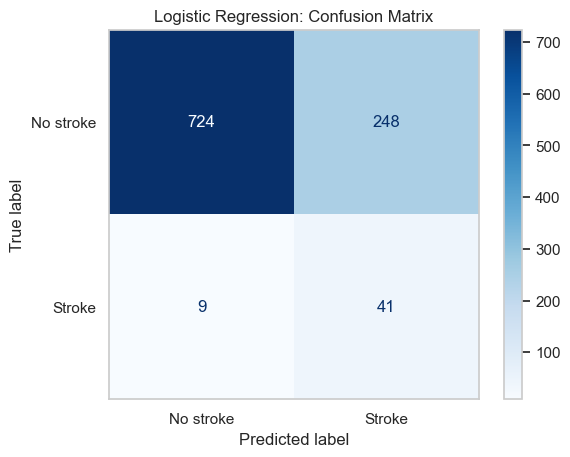

In [33]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['No stroke', 'Stroke'], cmap='Blues')
plt.title(best_name + ': Confusion Matrix')
plt.grid(False)
plt.show()

## ROC Curve & Precision-Recall Curve

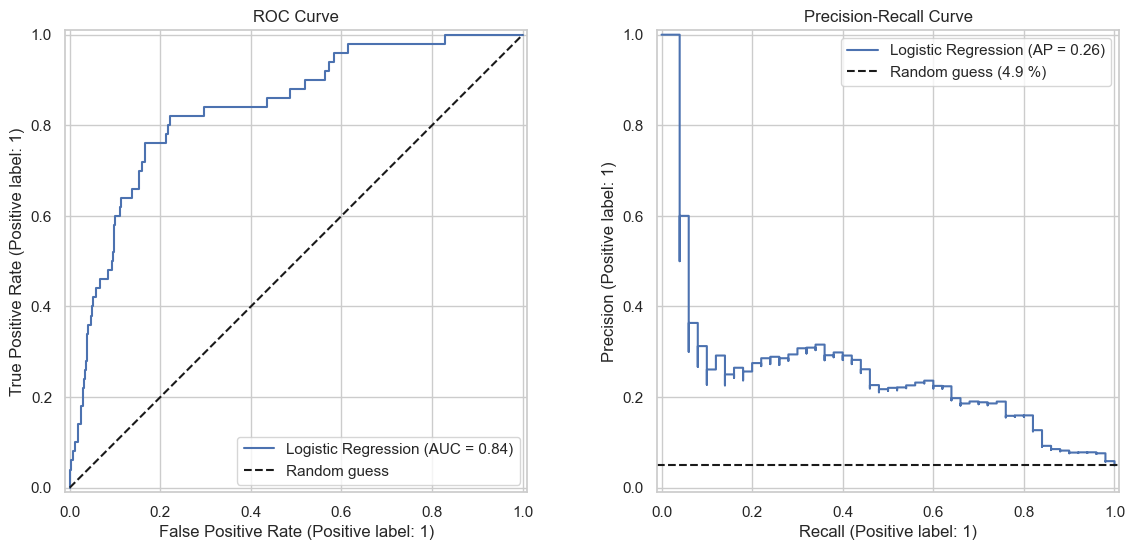

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

RocCurveDisplay.from_predictions(y_test, y_prob, name=best_name, ax=ax[0])
ax[0].plot([0, 1], [0, 1], 'k--', label='Random guess')
ax[0].set_title('ROC Curve')
ax[0].legend()

PrecisionRecallDisplay.from_predictions(y_test, y_prob, name=best_name, ax=ax[1])
ax[1].axhline(y_test.mean(), color='k', linestyle='--', label='Random guess (4.9 %)')
ax[1].set_title('Precision-Recall Curve')
ax[1].legend()
plt.show()

## Choosing the decision threshold

In [35]:
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (y_prob >= t).astype(int)
    print(f'threshold {t}:  recall = {recall_score(y_test, p):.2f}   precision = {precision_score(y_test, p):.2f}   patients flagged = {p.sum()}')

threshold 0.3:  recall = 0.84   precision = 0.09   patients flagged = 458
threshold 0.4:  recall = 0.84   precision = 0.11   patients flagged = 381
threshold 0.5:  recall = 0.82   precision = 0.14   patients flagged = 289
threshold 0.6:  recall = 0.76   precision = 0.17   patients flagged = 228
threshold 0.7:  recall = 0.64   precision = 0.20   patients flagged = 157


## Which features matter? (permutation importance on the test set)

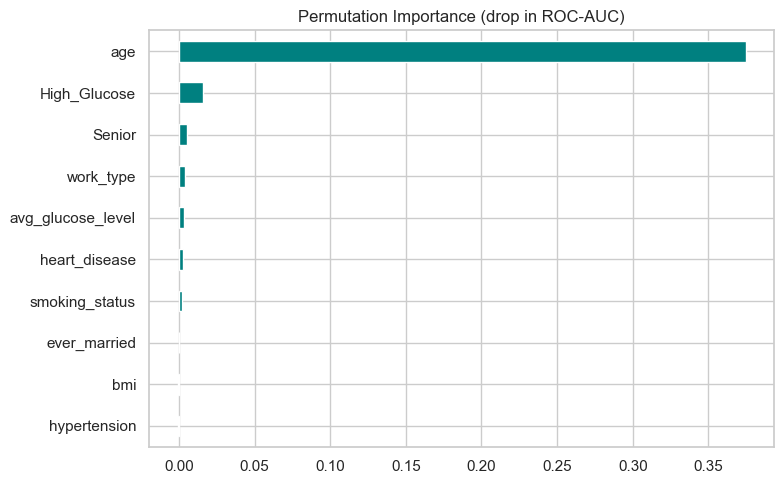

In [36]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=42, scoring='roc_auc', n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(8, 5))
importance.plot(kind='barh', color='teal')
plt.title('Permutation Importance (drop in ROC-AUC)')
plt.tight_layout()
plt.show()

**Interpretation of results**
- **GridSearchCV:** Logistic Regression C = 0.1 (a bit more regularization) → CV ROC-AUC 0.839 → 0.840; Random Forest improved the most (0.819 → 0.829 with `min_samples_leaf = 5`, less overfitting);
  LightGBM got slightly **worse** (0.820 → 0.818) because its default `num_leaves = 31` was not in the grid – a reminder to always include the default values in the grid.
  **Logistic Regression stays the best** and is the final model.
- **Test set:** ROC-AUC **0.839** (the same as CV → the model is stable, no overfitting), **recall 0.82** (41 of the 50 stroke patients are caught), precision 0.14, accuracy 0.75.
  Before vs after tuning on the test set is almost the same – tuning only changed the regularization slightly.
- **Confusion matrix:** 41 strokes caught, **only 9 missed**; 248 healthy patients are flagged as "at risk" (false alarms).
- **Why accept many false alarms?** In medical screening a **missed stroke is much worse** than an extra check-up. The threshold table shows the trade-off:
  threshold 0.7 → fewer false alarms but recall falls to 0.64; threshold 0.5 keeps recall high (0.82).
- **ROC curve** is far above the random line (AUC 0.84). The **Precision-Recall curve** (AP 0.26) is much better than random (0.05),
  but precision stays low because strokes are rare – this is normal for a 5 % problem.
- **Most important feature:** **age** by far, then High_Glucose and Senior (the engineered flags help) – hypertension and heart disease add little on top of age because they mostly happen in older patients.
- **Limits:** only 249 stroke cases (50 in the test set), so the test metrics can move a few points with a different split.

# Gradio App (deployment)
The final model is put into a small web app. The user enters the patient's information, the app adds the same two flags as in the
Feature Engineering step (`High_Glucose`, `Senior`) and shows the stroke risk.

- Only the features kept after Feature Selection are asked (gender and residence type were dropped).
- The tuned pipeline (`best_model`) is used directly, so the app gives exactly the same answers as the evaluation above.
- The score is a **risk score**, not an exact probability: SMOTE balanced the classes during training, so the scores are higher than the real 4.9 % stroke rate.
  The cut-off 0.5 is the same threshold used in the evaluation (recall 0.82).
- Run the cell below to open the app **inside the notebook** (or at the local link it prints).

In [37]:
import gradio as gr

def predict_stroke(age, avg_glucose_level, bmi, hypertension, heart_disease, ever_married, work_type, smoking_status):
    patient = pd.DataFrame([{
        'age': age, 'avg_glucose_level': avg_glucose_level, 'bmi': bmi,
        'hypertension': 1 if hypertension == 'Yes' else 0,
        'heart_disease': 1 if heart_disease == 'Yes' else 0,
        'ever_married': ever_married, 'work_type': work_type, 'smoking_status': smoking_status,
    }])
    patient['High_Glucose'] = int(avg_glucose_level >= 140)   # same feature engineering as above
    patient['Senior'] = int(age >= 60)

    risk = float(best_model.predict_proba(patient[num_cols + cat_cols])[0, 1])
    label = 'High risk – check-up recommended' if risk >= 0.5 else 'Low risk'
    return label, {'Stroke risk': risk, 'No stroke': 1 - risk}

demo = gr.Interface(
    fn=predict_stroke,
    inputs=[
        gr.Slider(1, 82, value=50, step=1, label='Age'),
        gr.Number(value=100, label='Average Glucose Level (mg/dL)'),
        gr.Number(value=28, label='BMI'),
        gr.Radio(['No', 'Yes'], value='No', label='Hypertension'),
        gr.Radio(['No', 'Yes'], value='No', label='Heart Disease'),
        gr.Radio(['No', 'Yes'], value='Yes', label='Ever Married'),
        gr.Dropdown(sorted(X_train['work_type'].unique()), value='Private', label='Work Type'),
        gr.Dropdown(sorted(X_train['smoking_status'].unique()), value='never smoked', label='Smoking Status'),
    ],
    outputs=[
        gr.Textbox(label='Prediction'),
        gr.Label(label='Risk score'),
    ],
    examples=[
        [67, 228.7, 36.6, 'No', 'Yes', 'Yes', 'Private', 'formerly smoked'],
        [25, 85.0, 22.0, 'No', 'No', 'No', 'Private', 'never smoked'],
        [45, 95.0, 27.0, 'No', 'No', 'Yes', 'Govt_job', 'smokes'],
    ],
    title='Stroke Risk Prediction',
    description='Enter the patient information to get a stroke risk (screening aid for learning purposes only – not a medical diagnosis).',
)

demo.launch()

Running on local URL:  http://127.0.0.1:7862

To create a public link, set `share=True` in `launch()`.


In [38]:
# quick check: the app function gives the same answers as the model
for p in [[67, 228.7, 36.6, 'No', 'Yes', 'Yes', 'Private', 'formerly smoked'],
          [25, 85.0, 22.0, 'No', 'No', 'No', 'Private', 'never smoked'],
          [45, 95.0, 27.0, 'No', 'No', 'Yes', 'Govt_job', 'smokes']]:
    label, scores = predict_stroke(*p)
    print(f'age = {p[0]}  glucose = {p[1]}  ->  {label}  (risk score {scores["Stroke risk"]:.2f})')

age = 67  glucose = 228.7  ->  High risk – check-up recommended  (risk score 0.77)
age = 25  glucose = 85.0  ->  Low risk  (risk score 0.03)
age = 45  glucose = 95.0  ->  Low risk  (risk score 0.24)


# Conclusions & Recommendations

**Conclusions**
1. The data is **very imbalanced** (4.9 % stroke), so ROC-AUC, recall and the PR curve were used instead of accuracy, and **SMOTE was applied inside the pipeline** (training folds only).
2. **Age** is the main risk factor, followed by high glucose, hypertension and heart disease; gender and residence type have no significant effect and were dropped.
3. 11 classification models were compared with stratified 5-fold CV; **Logistic Regression (C = 0.1)** was the best: test **ROC-AUC 0.84** and **recall 0.82**.
4. Complex models did **not** beat the simple one – with few positive cases, simple + regularized generalizes better.

**Recommendations**
- Use the model as a **screening tool** (flag patients for a check-up), not as a diagnosis; keep the threshold low to catch most stroke patients.
- Collect **more stroke cases** and more medical features (cholesterol, family history, blood pressure values) to raise precision.
- Choose the threshold together with doctors, based on the cost of a missed stroke vs. an extra check-up.